In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [18]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [19]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

y = df['Churn'].map({'Yes': 1, 'No': 0})
X = df.drop(columns=['Churn', 'customerID'])

X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
X['TotalCharges'] = X['TotalCharges'].fillna(X['TotalCharges'].median())

categorical_cols = X.select_dtypes(include='object').columns.tolist()
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("X shape:", X.shape, "| Churn ratio:\n", y.value_counts(normalize=True).round(3))

X shape: (7043, 30) | Churn ratio:
 Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


C:\Users\TECHNOSELLERS\AppData\Local\Temp\ipykernel_18576\2092630976.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns.tolist()


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)

(5634, 30) (1409, 30)


In [21]:
dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

dt_scores = {
    'Model': 'Decision Tree (Lab 3, depth=5)',
    'Accuracy':  accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall':    recall_score(y_test, y_pred_dt),
    'F1':        f1_score(y_test, y_pred_dt)
}
pd.DataFrame([dt_scores]).round(4)

,Model,Accuracy,Precision,Recall,F1
0,"Decision Tree (Lab 3, depth=5)",0.7942,0.6296,0.5455,0.5845


**Interpretation:** This is the Lab 3 model I selected after the depth analysis 
(max_depth = 5). On the held-out test set it scores 0.7942 accuracy, 0.6296 precision, 
0.5455 recall and 0.5845 F1. Because the dataset is imbalanced (~73.5% No / 26.5% Yes), 
accuracy is the least informative of these metrics — a model predicting "No churn" for 
everyone would already score ~73.5%. The recall of 0.5455 means the tree still misses 
nearly 45% of real churners. Every model in this lab will be judged primarily against 
this F1-score of 0.5845 and this recall.

In [22]:
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_scores = {
    'Model': 'Random Forest (default)',
    'Accuracy':  accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall':    recall_score(y_test, y_pred_rf),
    'F1':        f1_score(y_test, y_pred_rf)
}
pd.DataFrame([rf_scores]).round(4)

,Model,Accuracy,Precision,Recall,F1
0,Random Forest (default),0.7899,0.6336,0.4947,0.5556


**Why Random Forest may generalize better:** A single unrestricted Decision Tree 
tends to memorize the training data (as seen in Part 1, where the unrestricted tree 
scored 0.998 train accuracy but only 0.74 test accuracy). Random Forest trains many 
trees, each on a random bootstrap sample of the data and a random subset of features, 
then averages their votes. This reduces variance — the errors of individual trees 
(caused by memorizing noise) tend to cancel out when averaged, so the ensemble's 
predictions generalize better to unseen customers than any single tree's would.

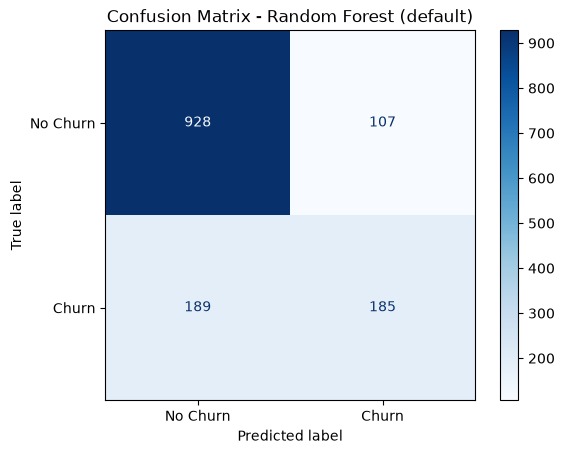

In [23]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Random Forest (default)")
plt.show()

In [24]:
comparison_df = pd.DataFrame([dt_scores, rf_scores]).round(4)
comparison_df

,Model,Accuracy,Precision,Recall,F1
0,"Decision Tree (Lab 3, depth=5)",0.7942,0.6296,0.5455,0.5845
1,Random Forest (default),0.7899,0.6336,0.4947,0.5556


### Interpretation (Task 7)

Out of 374 actual churners, the Random Forest correctly caught only 185 
(Recall = 0.4947) and missed 189. It also gave 107 false alarms.

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Decision Tree | 0.7942 | 0.6296 | 0.5455 | 0.5845 |
| Random Forest | 0.7899 | 0.6336 | 0.4947 | 0.5556 |

The Decision Tree is slightly better — higher Recall and F1, Random Forest only 
wins on Precision. The gap is small, not large.

Since the data is imbalanced (~73.5% No, 26.5% Yes), Recall and F1 matter most 
here — missing a real churner is worse than a false alarm. So the Decision Tree 
is currently the better model.



In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_cv_scores = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    X, y, cv=cv, scoring='f1'
)

rf_cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    X, y, cv=cv, scoring='f1'
)

print("Decision Tree F1 (5 folds):", dt_cv_scores.round(4))
print(f"Decision Tree — Mean F1: {dt_cv_scores.mean():.4f}, Std: {dt_cv_scores.std():.4f}\n")

print("Random Forest F1 (5 folds):", rf_cv_scores.round(4))
print(f"Random Forest — Mean F1: {rf_cv_scores.mean():.4f}, Std: {rf_cv_scores.std():.4f}")

Decision Tree F1 (5 folds): [0.6234 0.5596 0.5565 0.5378 0.5515]
Decision Tree — Mean F1: 0.5658, Std: 0.0298

Random Forest F1 (5 folds): [0.5719 0.5803 0.5482 0.5131 0.5146]
Random Forest — Mean F1: 0.5456, Std: 0.0280


### Interpretation (Task 9)

| Model | Single-split F1 | CV Mean F1 | CV Std |
|---|---|---|---|
| Decision Tree | 0.5845 | 0.5658 | 0.0298 |
| Random Forest | 0.5556 | 0.5456 | 0.0280 |

Cross-validation confirms the single-split result — the Decision Tree still beats 
the Random Forest, and the gap (~0.02 F1) is consistent across both approaches. 
This makes me more confident in the conclusion, since it isn't just luck from one 
particular split.

The single-split F1 for both models was slightly higher than their CV mean, which 
means the single test set happened to be a bit easier than average. The standard 
deviations (~0.03) are small and similar for both models, so neither model's 
performance is unusually unstable across folds.

In [26]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1   # sab CPU cores use karega, tez chalega
)

grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV F1 score:", round(grid_search.best_score_, 4))

Best params: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 300}
Best CV F1 score: 0.5696


In [27]:
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

tuned_scores = {
    'Model': 'Random Forest (tuned)',
    'Accuracy':  accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall':    recall_score(y_test, y_pred_tuned),
    'F1':        f1_score(y_test, y_pred_tuned)
}
pd.DataFrame([tuned_scores]).round(4)

,Model,Accuracy,Precision,Recall,F1
0,Random Forest (tuned),0.7984,0.65,0.5214,0.5786


### Interpretation (Task 11 & 12)

**Best hyperparameters:** `max_depth=15`, `min_samples_split=5`, `n_estimators=300`, 
found via 5-fold GridSearchCV with F1 as the scoring metric.

**Best cross-validated F1:** 0.5696

On the held-out test set, the tuned Random Forest scores:

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Decision Tree (depth=5) | 0.7942 | 0.6296 | 0.5455 | 0.5845 |
| Random Forest (default) | 0.7899 | 0.6336 | 0.4947 | 0.5556 |
| Random Forest (tuned) | 0.7984 | 0.6500 | 0.5214 | 0.5786 |

Tuning helped — the Random Forest's F1 improved from 0.5556 (default) to 0.5786 
(tuned), and it now has the highest Accuracy and Precision of the three models. 
However, it still hasn't quite caught up to the Decision Tree's F1 of 0.5845, 
mainly because its Recall (0.5214) is still lower than the Decision Tree's 
(0.5455). This shows tuning closes most, but not all, of the gap — for this 
dataset, a well-chosen single tree remains a strong, competitive baseline.

In [28]:
final_comparison = pd.DataFrame([dt_scores, rf_scores, tuned_scores]).round(4)
final_comparison

,Model,Accuracy,Precision,Recall,F1
0,"Decision Tree (Lab 3, depth=5)",0.7942,0.6296,0.5455,0.5845
1,Random Forest (default),0.7899,0.6336,0.4947,0.5556
2,Random Forest (tuned),0.7984,0.6500,0.5214,0.5786


tenure                                 0.421435
InternetService_Fiber optic            0.357542
TotalCharges                           0.047129
PaymentMethod_Electronic check         0.036761
MultipleLines_Yes                      0.023630
OnlineSecurity_No internet service     0.020669
Contract_Two year                      0.019599
StreamingMovies_No internet service    0.017379
MonthlyCharges                         0.016847
TechSupport_Yes                        0.012988
dtype: float64


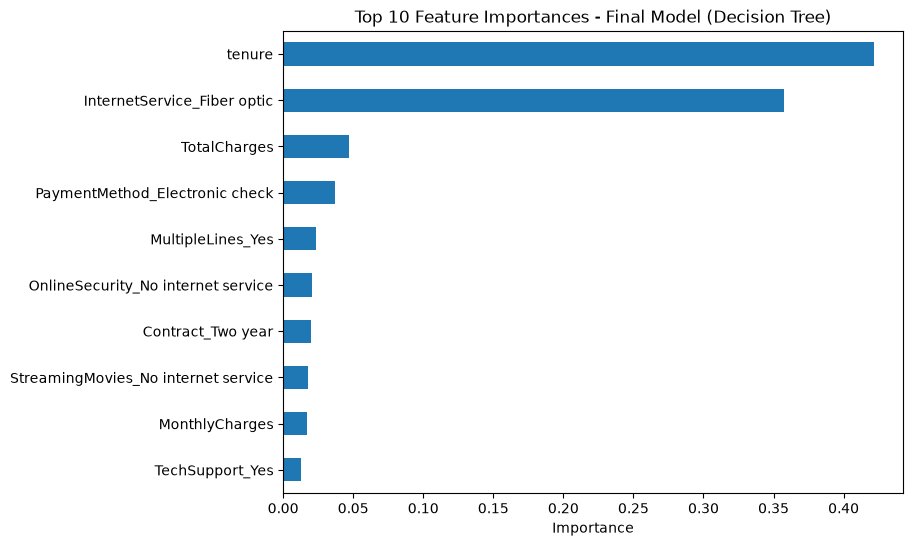

In [29]:
final_model = dt   # Decision Tree jeeta hai F1 ke hisaab se

importances = pd.Series(final_model.feature_importances_, index=X.columns)
importances_sorted = importances.sort_values(ascending=False)

print(importances_sorted.head(10))

plt.figure(figsize=(8,6))
importances_sorted.head(10).plot(kind='barh')
plt.xlabel('Importance')
plt.title('Top 10 Feature Importances - Final Model (Decision Tree)')
plt.gca().invert_yaxis()
plt.show()

**Final model selection:** I selected the Decision Tree (max_depth=5) as the final 
model. It has the highest F1-score (0.5845) and highest Recall (0.5455) among all 
three models tested, both in the single-split evaluation and in 5-fold cross-validation. 
Although the tuned Random Forest came close (F1 = 0.5786) and had slightly better 
Precision, Recall matters more for this churn problem, and the Decision Tree wins 
there. Choosing the tuned Random Forest just because it's a more complex model would 
not be justified by the evidence in the table above.

### Interpretation (Task 15)

The top 5 features driving the final model's predictions are:

1. **tenure** (0.4214) — how long the customer has stayed
2. **InternetService_Fiber optic** (0.3575) — whether they use fiber optic internet
3. **TotalCharges** (0.0471)
4. **PaymentMethod_Electronic check** (0.0368)
5. **MultipleLines_Yes** (0.0236)

Together, tenure and Fiber optic internet account for over 77% of the model's 
decision-making — the tree relies almost entirely on these two features to predict 
churn, with everything else playing a minor supporting role.

This matches what Lab 2's EDA and Lab 3's Decision Tree both found: customers with 
short tenure and those on Fiber optic plans churn more. This consistency across 
three different labs and models suggests these are genuine, business-relevant churn 
drivers rather than noise the model happened to pick up. It makes sense practically 
too — Fiber optic customers often pay more and may face more service issues, and 
newer (low-tenure) customers haven't built loyalty yet, so they leave more easily.|

## 10. Kaggle Prediction/Submission

In [30]:
test_customer_ids = df.loc[X_test.index, 'customerID']

y_pred_final = final_model.predict(X_test)

submission = pd.DataFrame({
    'customerID': test_customer_ids.values,
    'Churn': pd.Series(y_pred_final).map({1: 'Yes', 0: 'No'})
})

submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

(1409, 2)


,customerID,Churn
0,4376-KFVRS,No
1,2754-SDJRD,Yes
2,9917-KWRBE,No
3,0365-GXEZS,No
4,9385-NXKDA,No


**Future work:** With more time, we would address the class imbalance directly — 
e.g. using `class_weight='balanced'` in both models, or oversampling the minority 
(churn) class with SMOTE — since Recall is still the weakest metric. We would also 
try Gradient Boosting or XGBoost, which often outperform Random Forest on tabular 
data, and do more feature engineering (e.g. tenure buckets, or an interaction term 
between Contract type and MonthlyCharges), since Contract type appeared relevant 
in the feature importance ranking but was not deeply explored here.